# PINN for the wind turbine (ODE) — forward solve and inertia identification

The ODE counterpart of the wake PINN: a physics-informed network for the **turbine drivetrain**.
Below rated wind the rotor spins up under region-II control,
$$J\,\dot\omega = T_{\text{aero}}(\omega,v) - K\omega^2,\qquad
T_{\text{aero}}=\frac{\tfrac12\rho A\,C_p(\lambda)\,v^3}{\omega},\quad \lambda=\frac{\omega R}{v}.$$
We (1) solve the spin-up with a PINN (hard initial condition), and (2) **identify the drivetrain
inertia $J$** from noisy rotor-speed data --- a real commissioning / digital-twin task. Ground truth
is the Chapter-1 turbine.

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0
V0, T, W0 = 9.0, 120.0, 0.30     # constant region-II wind [m/s], time window [s], start speed [rad/s]
J_TRUE = 38.6e6                  # drivetrain inertia [kg m^2]
STEPS_FWD = 14000
N_DATA, NOISE = 40, 0.01         # rotor-speed samples and their noise std [rad/s]
J_INIT_FACTOR = 2.0              # initial guess = factor * true J
STEPS_INV, W_DATA = 6000, 50.0
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, V0=9.0, T=120.0, W0=0.30, J_TRUE=38.6e6, STEPS_FWD=14000,
                N_DATA=40, NOISE=0.01, J_INIT_FACTOR=2.0, STEPS_INV=6000, W_DATA=50.0)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch
import matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP, grad
torch.set_default_dtype(torch.float64); torch.manual_seed(SEED); np.random.seed(SEED)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg

rho, R, Cp_max, P_rated = 1.225, 63.0, 0.48, 5.0e6; A = np.pi*R**2
J_true = J_TRUE; lam_opt = 8.10
K = 0.5*rho*A*R**3*Cp_max/lam_opt**3
def Cp_np(lam):
    lam = np.maximum(lam, 1e-6); li = 1/(1/lam - 0.035)
    return np.maximum(0.5176*(116/li - 5)*np.exp(-21/li) + 0.0068*lam, 0)
def Cp_t(lam):
    lam = torch.clamp(lam, min=1e-6); li = 1/(1/lam - 0.035)
    return torch.clamp(0.5176*(116/li - 5)*torch.exp(-21/li) + 0.0068*lam, min=0)

v0, w0 = V0, W0
w_eq = lam_opt*v0/R
def rhs(w, J): return (0.5*rho*A*Cp_np(w*R/v0)*v0**3/max(w, 0.1) - K*w**2)/J
def rk4_spinup(J, dt=0.05):
    n = int(T/dt); t = np.linspace(0, n*dt, n+1); w = w0; W = [w]
    for k in range(n):
        k1 = rhs(w, J); k2 = rhs(w+0.5*dt*k1, J); k3 = rhs(w+0.5*dt*k2, J); k4 = rhs(w+dt*k3, J)
        w = max(w + dt/6*(k1+2*k2+2*k3+k4), 0.05); W.append(w)
    return t, np.array(W)
t_gt, w_gt = rk4_spinup(J_true)
print(f"omega_eq = {w_eq:.3f} rad/s,  spin-up reaches {w_gt[-1]:.3f} by t={T:.0f}s")

omega_eq = 1.157 rad/s,  spin-up reaches 1.157 by t=120s


## 1. Forward PINN: the spin-up

The ansatz $\hat\omega(t)=\omega_0 + t\,\mathrm{NN}(t)$ satisfies $\omega(0)=\omega_0$ exactly, so
the loss is the physics residual $J\dot{\hat\omega}-(T_{\text{aero}}-K\hat\omega^2)$ alone (scaled by
$J$ to read in rad/s$^2$). The PINN matches the RK4 spin-up to a fraction of a percent.

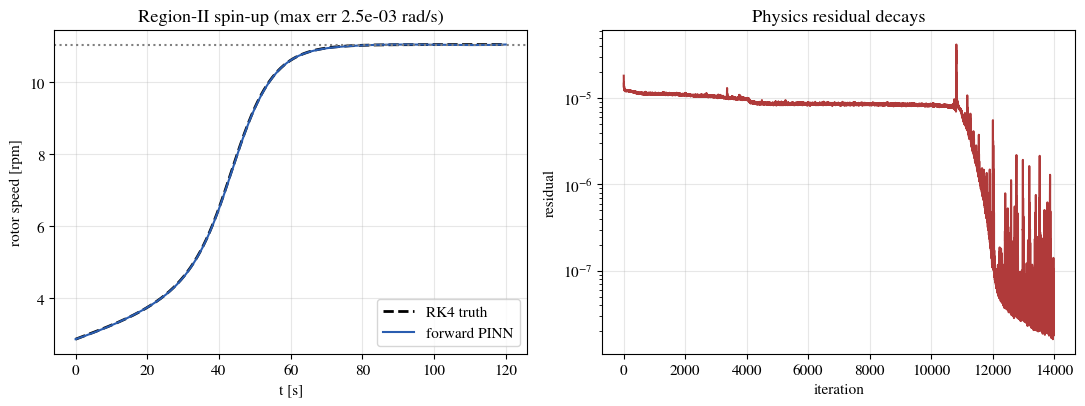

max abs error vs RK4: 0.0024963134990083624


In [3]:
net = MLP([1, 32, 32, 1])
def w_hat(t): return w0 + (t/T)*net(t/T)              # hard IC at t=0
def rhs_t(w, J):
    return (0.5*rho*A*Cp_t(w*R/v0)*v0**3/torch.clamp(w, min=0.1) - K*w**2)/J
def train_forward(steps=STEPS_FWD, lr=2e-3):
    opt = torch.optim.Adam(net.parameters(), lr); hist = []
    for e in range(steps):
        t = (torch.rand(2000, 1)*T).requires_grad_(True)
        w = w_hat(t); w_t = grad(w, t)
        loss = ((w_t - rhs_t(w, J_true))**2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
    return hist
hist = train_forward()
tt = torch.linspace(0, T, 300).reshape(-1, 1)
with torch.no_grad(): wp = w_hat(tt).numpy().ravel()
err = np.abs(np.interp(t_gt, tt.numpy().ravel(), wp) - w_gt).max()

def plot_wind_pinn_forward():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(t_gt, w_gt*30/np.pi, '--', color=fg(), lw=2, label='RK4 truth')
    ax[0].plot(tt.numpy().ravel(), wp*30/np.pi, 'C0', label='forward PINN')
    ax[0].axhline(w_eq*30/np.pi, ls=':', c='gray')
    ax[0].set(xlabel='t [s]', ylabel='rotor speed [rpm]',
              title=f'Region-II spin-up (max err {err:.1e} rad/s)'); ax[0].legend()
    ax[1].semilogy(hist, 'C3'); ax[1].set(xlabel='iteration', ylabel='residual', title='Physics residual decays')
    plt.tight_layout()

save_dual(plot_wind_pinn_forward, 'wind_pinn_forward', FIG)
plt.show()
print('max abs error vs RK4:', err)

## 2. Inverse PINN: identify the drivetrain inertia $J$

The inertia $J$ (rotor + drivetrain) is a key commissioning parameter and drifts with maintenance.
Make it trainable and fit noisy rotor-speed samples from a logged spin-up: the physics residual (with
trainable $J$) plus a data term recover $J$ from a deliberately wrong initial guess.

/var/folders/px/kfx0kpc11td_5_f5ny95_wrh0000gn/T/ipykernel_10438/3894712169.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  rec.append(float(torch.exp(log_J)))


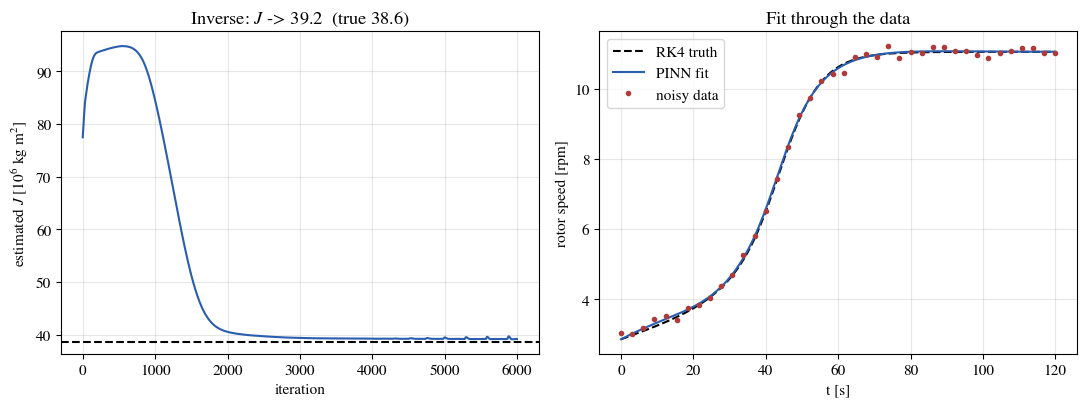

recovered J = 39.23e6  (true 38.60e6), error 1.6%


In [4]:
nd = N_DATA; idx = np.linspace(0, len(t_gt)-1, nd).astype(int)
td = torch.tensor(t_gt[idx]).reshape(-1, 1)
wd = torch.tensor(w_gt[idx] + NOISE*np.random.randn(nd)).reshape(-1, 1)   # noisy SCADA-like data
net2 = MLP([1, 32, 32, 1])
def w2(t): return w0 + (t/T)*net2(t/T)
log_J = torch.tensor(np.log(J_INIT_FACTOR*J_true), requires_grad=True)   # deliberate overestimate
opt = torch.optim.Adam(list(net2.parameters()) + [log_J], lr=3e-3)
rec = []
for e in range(STEPS_INV):
    J = torch.exp(log_J)
    t = (torch.rand(1500, 1)*T).requires_grad_(True)
    w = w2(t); w_t = grad(w, t)
    Lr = ((w_t - rhs_t(w, J))**2).mean()
    Ld = ((w2(td) - wd)**2).mean()
    opt.zero_grad(); (Lr + W_DATA*Ld).backward(); opt.step()
    rec.append(float(torch.exp(log_J)))
with torch.no_grad(): wfit = w2(tt).numpy().ravel()

def plot_wind_pinn_inverse():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(np.array(rec)/1e6, 'C0'); ax[0].axhline(J_true/1e6, ls='--', c=fg())
    ax[0].set(xlabel='iteration', ylabel='estimated $J$ [$10^6$ kg m$^2$]',
              title=f"Inverse: $J$ -> {rec[-1]/1e6:.1f}  (true {J_true/1e6:.1f})")
    ax[1].plot(t_gt, w_gt*30/np.pi, '--', color=fg(), label='RK4 truth')
    ax[1].plot(tt.numpy().ravel(), wfit*30/np.pi, 'C0', label='PINN fit')
    ax[1].plot(t_gt[idx], wd.numpy().ravel()*30/np.pi, 'C3.', ms=6, label='noisy data')
    ax[1].set(xlabel='t [s]', ylabel='rotor speed [rpm]', title='Fit through the data'); ax[1].legend()
    plt.tight_layout()

save_dual(plot_wind_pinn_inverse, 'wind_pinn_inverse', FIG)
plt.show()
print(f'recovered J = {rec[-1]/1e6:.2f}e6  (true {J_true/1e6:.2f}e6), '
      f'error {abs(rec[-1]-J_true)/J_true*100:.1f}%')

In [5]:
J_err = abs(rec[-1]-J_true)/J_true
assert np.isfinite(hist).all() and err < 0.02, f"forward spin-up max error {err:.2e} rad/s"
assert J_err < 0.1, f"J recovered within 10 % (got {J_err:.1%})"
if AT_DEFAULTS:
    # numbers quoted on the slides and in notes/applications.tex
    assert err < 5e-3, f"spin-up max error {err:.1e}"
    assert J_err < 0.03, f"J error {J_err:.1%}"
    print(f'slide numbers: spin-up max err {err:.1e} rad/s, J error {J_err:.1%}')
else:
    print('regression check skipped (parameters differ from the slide defaults)')

slide numbers: spin-up max err 2.5e-03 rad/s, J error 1.6%


**Takeaway.** The same PINN that *solves* the spin-up also *identifies* the drivetrain inertia
from noisy operating data --- the wind analogue of the vessel parameter identification. The companion
PDE problem, recovering the wake's eddy viscosity from LiDAR-like data, is in
\texttt{pinn\_wind\_pde.ipynb}; both feed the digital twin. When the missing physics is an unknown
*function* rather than a parameter, the hybrid CoSTA approach (Chapter~\ref{ch:costa}) takes over.